# 2 · Network profitability and cross-subsidy

**Decision:** identify where NorthByte's network earns or consumes contribution, and distinguish a route review priority from a defensible route closure decision. All amounts are Canadian dollars. This report compares September–August fiscal years before gate leases.

## tl;dr

The loss pool overwhelms the profitable routes. In FY2025–26, 26 of 54 directional routes generated CAD 12.37m of positive contribution; 28 consumed CAD 61.04m. The surplus covered 20.3% of those losses, versus 54.2% one year earlier. Net contribution fell from CAD -12.57m to CAD -48.67m.

The largest problem is concentrated in major corridors. Montreal↔Vancouver's two directions lost CAD 19.72m, 32.3% of the gross route loss pool. The eight most deteriorating directions account for CAD 25.69m, or 71.2% of the year-over-year decline. Calgary departure operations remain positive; Montreal, Toronto, Halifax, and Vancouver lead departure-side losses. All four broad network segments are net negative, even though each of the three hub-related groups contains profitable routes.

Date scope matters: 759 assumed-day-first transactions totalling CAD 499,209.97 net revenue fall outside the study period and are excluded. This is a pre-gate, mixed-clock contribution comparison; route closure savings and connecting-network effects are not established.

“Contribution” throughout means **net purchase-date transaction revenue minus flight-date operating costs**; it is a period-based screening proxy, not matched-flight or fully loaded profit.

In [1]:
from pathlib import Path
import sys

ROOT = (
    Path.cwd()
    if (Path.cwd() / "src/analysis_common.py").exists()
    else Path.cwd().parent
)
sys.path.insert(0, str(ROOT / "src"))
from analysis_common import (
    load_data,
    setup_style,
    save_figure,
    save_table,
    FY_ORDER,
    COLORS,
)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown

setup_style()
pd.set_option("display.max_rows", 24)
pd.set_option("display.max_columns", 16)
HUBS = {"YVR", "YYC", "YYZ", "YUL"}
SEGMENTS = ["Hub → hub", "Hub → non-hub", "Non-hub → hub", "Non-hub → non-hub"]
transactions_all = load_data("transactions")
costs_all = load_data("costs")
route_dimension = load_data("routes")
transactions = transactions_all.loc[transactions_all.in_scope].copy()
costs = costs_all.loc[costs_all.in_scope].copy()


def money(v):
    return f"CAD {v:,.2f}"


def million(v):
    return f"CAD {v/1e6:,.2f}m"


def show_table(frame, formats=None):
    labels = {
        "fiscal_year": "Fiscal year",
        "source": "Source",
        "rows": "Rows",
        "amount_cad": "Amount (CAD)",
        "route_id": "Direction",
        "departure_airport": "Departure",
        "segment": "Segment",
        "corridor": "Corridor",
        "revenue_cad": "Revenue (CAD)",
        "operating_cost_cad": "Flight costs (CAD)",
        "contribution_cad": "Contribution (CAD)",
        "contribution_margin_pct": "Margin (%)",
        "flights": "Flights",
        "directional_routes": "Directions",
        "profitable_routes": "Positive routes",
        "loss_making_routes": "Negative routes",
        "profitable_surplus_cad": "Surplus (CAD)",
        "loss_pool_cad": "Loss pool (CAD)",
        "net_contribution_cad": "Net (CAD)",
        "loss_pool_covered_pct": "Coverage (%)",
        "contribution_per_flight_cad": "Contribution / flight (CAD)",
        "fy2024_25_contribution_cad": "FY2024–25 (CAD)",
        "fy2025_26_contribution_cad": "FY2025–26 (CAD)",
        "change_cad": "Change (CAD)",
    }
    display(
        frame.rename(columns=labels)
        .style.format(
            {labels.get(c, c): f for c, f in (formats or {}).items()}, na_rep="—"
        )
        .hide(axis="index")
    )


def dollars(frame):
    result = frame.copy()
    for c in [c for c in result if c.endswith("_cents")]:
        result[c.replace("_cents", "_cad")] = result.pop(c) / 100
    return result

## Context & Methods

The case package identifies Vancouver (YVR), Calgary (YYC), Toronto (YYZ), and Montreal (YUL) as the four hubs. Each directional route belongs to exactly one of four groups: hub→hub, hub→non-hub, non-hub→hub, or non-hub→non-hub. These are operating-network groupings, not passenger itinerary classifications.

### Key assumptions

- **Dates:** use the cleaned timestamps without reinterpreting already parsed or duplicate-resolved dates. Only the remaining 7,902 ambiguous rows carry the user's DD/MM/YYYY assumption (`date_status=assumed_day_first`). Rows outside 1 September 2024 through 31 August 2026 are excluded and reconciled below.
- **Financial measure:** signed transaction amounts already include negative refunds. Subtract all four supplied flight cost types (fuel, crew, maintenance, food). Gate leases and any costs outside these files are excluded. No arbitrary gate-cost allocation is introduced.
- **Timing:** ticket purchase time and flight time are different clocks. This analysis cannot recognize revenue on the actual flown date or estimate true per-flight yields, load factors, or avoidable costs.
- **Joins:** independently aggregate revenue and costs to fiscal year × directional route, then join one-to-one. The flight count uses unique route × flight timestamp only after verifying exactly four distinct cost categories per group.
- **Airport view:** attribute each route to its **departure airport only**. Airport and segment totals therefore reconcile to the airline total. Adding arrivals to departures would count each route twice.
- **Cross-subsidy:** compare the sum of positive route contributions with the absolute sum of negative route contributions. This is a financial pooling illustration; it does not trace cash transfers or prove that connecting routes are economically dispensable.

## Data

Sources are `data/processed/transactions.csv`, `costs.csv`, and `routes.csv`; field meanings come from the supplied *FirstByte 2026 Data Dictionary* (pages 1–3) and the case package (company/network context). Transaction grain is one monetary event, cost grain is one flight cost category, and route dimension grain is one directional route. Monetary reconciliation uses integer cents.

In [2]:
assert transactions_all.transaction_id.is_unique
assert costs_all.cost_id.is_unique
assert route_dimension.route_id.is_unique
assert (
    transactions_all.transaction_date.notna().all()
    and costs_all.cost_date.notna().all()
)
assert (
    set(transactions.route_id) == set(costs.route_id) == set(route_dimension.route_id)
)
assert (
    route_dimension.route_id
    == route_dimension.departure_airport + route_dimension.arrival_airport
).all()
expected_types = {"Fuel", "Crew", "Maintenance", "Food"}
flight_groups = costs.groupby(["fiscal_year", "route_id", "cost_date"])
flight_check = flight_groups.agg(
    cost_rows=("cost_type", "size"), cost_types=("cost_type", "nunique")
)
assert set(costs.cost_type) == expected_types
assert flight_check.cost_rows.eq(4).all() and flight_check.cost_types.eq(4).all()
assert not costs.duplicated(["route_id", "cost_date", "cost_type"]).any()
flight_counts = (
    flight_check.groupby(["fiscal_year", "route_id"]).size().rename("flights")
)
revenue = transactions.groupby(["fiscal_year", "route_id"]).agg(
    revenue_cents=("amount_cents", "sum"), transaction_rows=("transaction_id", "size")
)
operating = costs.groupby(["fiscal_year", "route_id"]).agg(
    operating_cost_cents=("amount_cents", "sum")
)
route = revenue.join(operating, how="outer", validate="one_to_one").join(
    flight_counts, validate="one_to_one"
)
assert route.notna().all().all()
route = route.reset_index().merge(
    route_dimension, on="route_id", how="left", validate="many_to_one"
)
route["contribution_cents"] = route.revenue_cents - route.operating_cost_cents
route["contribution_margin_pct"] = 100 * route.contribution_cents / route.revenue_cents
route["contribution_per_flight_cad"] = route.contribution_cents / 100 / route.flights
route["revenue_per_flight_proxy_cad"] = route.revenue_cents / 100 / route.flights
route["operating_cost_per_flight_cad"] = (
    route.operating_cost_cents / 100 / route.flights
)
route["segment"] = np.select(
    [
        route.departure_airport.isin(HUBS) & route.arrival_airport.isin(HUBS),
        route.departure_airport.isin(HUBS),
        route.arrival_airport.isin(HUBS),
    ],
    SEGMENTS[:3],
    default=SEGMENTS[3],
)
route["corridor"] = route.apply(
    lambda r: " ↔ ".join(sorted([r.departure_airport, r.arrival_airport])), axis=1
)
route = dollars(route)
annual = (
    route.groupby("fiscal_year")[
        ["revenue_cad", "operating_cost_cad", "contribution_cad", "flights"]
    ]
    .sum()
    .reindex(FY_ORDER)
)
# Independent source-level integer-cent checks prevent an unnoticed join expansion.
for fy in FY_ORDER:
    for source, col in [(transactions, "revenue_cad"), (costs, "operating_cost_cad")]:
        assert (
            round(annual.loc[fy, col] * 100)
            == source.loc[source.fiscal_year.eq(fy), "amount_cents"].sum()
        )
assert len(route) == 108 and route.groupby("fiscal_year").size().eq(54).all()
scope_audit = pd.concat(
    [
        transactions_all.groupby("fiscal_year")
        .agg(rows=("transaction_id", "size"), amount_cents=("amount_cents", "sum"))
        .assign(source="Transactions"),
        costs_all.groupby("fiscal_year")
        .agg(rows=("cost_id", "size"), amount_cents=("amount_cents", "sum"))
        .assign(source="Operating costs"),
    ]
).reset_index()
scope_audit = dollars(scope_audit)[["source", "fiscal_year", "rows", "amount_cad"]]
date_audit = dollars(
    transactions_all.groupby(["date_status", "fiscal_year"])
    .agg(rows=("transaction_id", "size"), net_revenue_cents=("amount_cents", "sum"))
    .reset_index()
)
assert transactions_all.date_status.eq("assumed_day_first").sum() == 7902
assert (~transactions_all.in_scope).sum() == 759
assert (
    transactions_all.loc[~transactions_all.in_scope, "date_status"]
    .eq("assumed_day_first")
    .all()
)
save_table(scope_audit, "02_scope_reconciliation")
save_table(date_audit, "02_date_status_reconciliation")
show_table(scope_audit, {"amount_cad": "{:,.2f}"})

Source,Fiscal year,Rows,Amount (CAD)
Transactions,FY2024-25,269811,"180,419,443.08"
Transactions,FY2025-26,287559,"189,710,371.80"
Transactions,Outside study period,759,"499,209.97"
Operating costs,FY2024-25,52288,"192,985,563.99"
Operating costs,FY2025-26,62916,"238,376,476.25"


In [3]:
pools = (
    route.groupby("fiscal_year")
    .agg(
        profitable_routes=("contribution_cad", lambda s: int((s > 0).sum())),
        loss_making_routes=("contribution_cad", lambda s: int((s < 0).sum())),
        profitable_surplus_cad=("contribution_cad", lambda s: s[s > 0].sum()),
        loss_pool_cad=("contribution_cad", lambda s: -s[s < 0].sum()),
        net_contribution_cad=("contribution_cad", "sum"),
    )
    .reindex(FY_ORDER)
)
pools["loss_pool_covered_pct"] = (
    pools.profitable_surplus_cad / pools.loss_pool_cad * 100
)
pools["net_margin_pct"] = pools.net_contribution_cad / annual.revenue_cad * 100
pools["profitable_route_revenue_share_pct"] = (
    route.loc[route.contribution_cad.gt(0)].groupby("fiscal_year").revenue_cad.sum()
    / annual.revenue_cad
    * 100
)
latest = route.loc[route.fiscal_year.eq(FY_ORDER[1])].copy()
route_change = route.pivot(
    index="route_id", columns="fiscal_year", values="contribution_cad"
).reset_index()
route_change.columns = [
    "route_id",
    "fy2024_25_contribution_cad",
    "fy2025_26_contribution_cad",
]
route_change["change_cad"] = (
    route_change.fy2025_26_contribution_cad - route_change.fy2024_25_contribution_cad
)
route_change = route_change.merge(
    route_dimension, on="route_id", validate="one_to_one"
).sort_values("change_cad")
negative_latest = latest.loc[latest.contribution_cad.lt(0)].sort_values(
    "contribution_cad"
)
positive_latest = latest.loc[latest.contribution_cad.gt(0)].sort_values(
    "contribution_cad", ascending=False
)
change_total = (
    annual.loc[FY_ORDER[1], "contribution_cad"]
    - annual.loc[FY_ORDER[0], "contribution_cad"]
)
top2_loss = -negative_latest.head(2).contribution_cad.sum()
top8_decline = -route_change.head(8).change_cad.sum()
airport = (
    route.groupby(["fiscal_year", "departure_airport"])
    .agg(
        revenue_cad=("revenue_cad", "sum"),
        operating_cost_cad=("operating_cost_cad", "sum"),
        contribution_cad=("contribution_cad", "sum"),
        flights=("flights", "sum"),
        directional_routes=("route_id", "nunique"),
        profitable_routes=("contribution_cad", lambda s: (s > 0).sum()),
    )
    .reset_index()
)
airport["contribution_margin_pct"] = (
    airport.contribution_cad / airport.revenue_cad * 100
)
airport["contribution_per_flight_cad"] = airport.contribution_cad / airport.flights
segment = (
    route.groupby(["fiscal_year", "segment"])
    .agg(
        revenue_cad=("revenue_cad", "sum"),
        operating_cost_cad=("operating_cost_cad", "sum"),
        contribution_cad=("contribution_cad", "sum"),
        flights=("flights", "sum"),
        directional_routes=("route_id", "nunique"),
        profitable_routes=("contribution_cad", lambda s: (s > 0).sum()),
    )
    .reset_index()
)
segment["contribution_margin_pct"] = (
    segment.contribution_cad / segment.revenue_cad * 100
)
segment["contribution_per_flight_cad"] = segment.contribution_cad / segment.flights
corridor = (
    route.groupby(["fiscal_year", "corridor"])
    .agg(
        revenue_cad=("revenue_cad", "sum"),
        operating_cost_cad=("operating_cost_cad", "sum"),
        contribution_cad=("contribution_cad", "sum"),
        flights=("flights", "sum"),
        directions=("route_id", "nunique"),
    )
    .reset_index()
)
assert corridor.directions.eq(2).all()
for aggregation in [airport, segment, corridor]:
    check = (
        aggregation.groupby("fiscal_year")[
            ["revenue_cad", "operating_cost_cad", "contribution_cad", "flights"]
        ]
        .sum()
        .reindex(FY_ORDER)
    )
    np.testing.assert_allclose(check, annual, rtol=0, atol=1e-6)
for frame, stem in [
    (route, "02_directional_route_profitability"),
    (route_change, "02_directional_route_changes"),
    (airport, "02_departure_airport_profitability"),
    (segment, "02_network_segments"),
    (corridor, "02_two_way_corridors"),
    (pools.reset_index(), "02_cross_subsidy_pools"),
]:
    save_table(frame, stem)
excluded_cad = (
    transactions_all.loc[~transactions_all.in_scope, "amount_cents"].sum() / 100
)
summary = f"""**The loss pool overwhelms the profitable routes.** In FY2025–26, **{int(pools.iloc[1].profitable_routes)} of 54 directional routes** generated {million(pools.iloc[1].profitable_surplus_cad)} of positive contribution; **{int(pools.iloc[1].loss_making_routes)}** consumed {million(pools.iloc[1].loss_pool_cad)}. The surplus covered **{pools.iloc[1].loss_pool_covered_pct:.1f}%** of those losses, versus {pools.iloc[0].loss_pool_covered_pct:.1f}% one year earlier. Net contribution fell from {million(annual.iloc[0].contribution_cad)} to **{million(annual.iloc[1].contribution_cad)}**.

**The largest problem is concentrated in major corridors.** Montreal↔Vancouver's two directions lost {million(top2_loss)}, **{100*top2_loss/pools.iloc[1].loss_pool_cad:.1f}% of the gross route loss pool**. The eight most deteriorating directions account for {million(top8_decline)}, or {100*top8_decline/(-change_total):.1f}% of the year-over-year decline. Calgary departure operations remain positive; Montreal, Toronto, Halifax, and Vancouver lead departure-side losses. All four broad network segments are net negative, even though each of the three hub-related groups contains profitable routes.

**Date scope matters:** 759 assumed-day-first transactions totalling **{money(excluded_cad)} net revenue** fall outside the study period and are excluded. This is a pre-gate, mixed-clock contribution comparison; route closure savings and connecting-network effects are not established."""
display(
    Markdown(
        "**Checks passed:** 108 route-year rows; complete four-category flight-cost grain; additive airport, segment and corridor reconciliations. The exact summary appears at the top of this notebook."
    )
)

**Checks passed:** 108 route-year rows; complete four-category flight-cost grain; additive airport, segment and corridor reconciliations. The exact summary appears at the top of this notebook.

The audit above reconciles every retained row and cent to the source files. All 28,801 candidate flights have four cost rows and four distinct cost types; this supports counting one flight per route/timestamp. Revenue and operating costs cover the same 54 directions in both years. The exported date-status table separately preserves parsed, duplicate-resolved, and assumed-day-first populations; exclusions are not silently assigned to a fiscal year.

## Results

### 1. Profitable routes provide a shrinking cushion

Positive and negative pools are classified **within each fiscal year**. A route can therefore change pools. Gross losses are larger than the airline's net loss because the profitable pool offsets part of them.

Fiscal year,Positive routes,Negative routes,Surplus (CAD),Loss pool (CAD),Coverage (%)
FY2024-25,30,24,"14,872,348.92","27,438,469.83",54.20
FY2025-26,26,28,"12,369,894.81","61,035,999.26",20.27


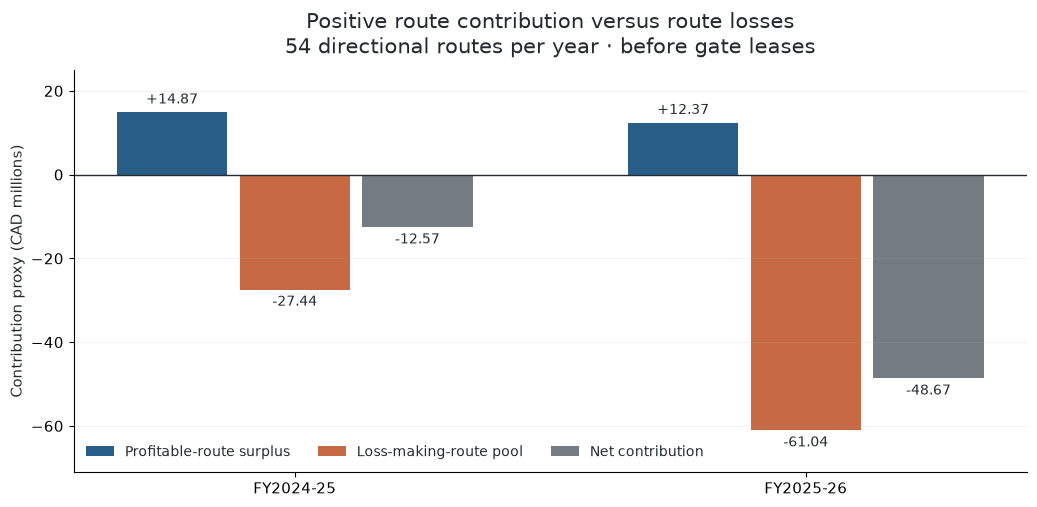

The positive pool shrank by **CAD 2.50m**, while the gross loss pool expanded by **CAD 33.60m**. Together these explain the CAD 36.10m net deterioration. Profitable routes supply an offset, but cannot fully fund loss-making routes: the residual gap is CAD 48.67m before gates. The revenue-weighted net margin proxy is -25.7%; the positive-route share of net revenue is 62.3%.

In [4]:
show_table(
    pools.reset_index()[
        [
            "fiscal_year",
            "profitable_routes",
            "loss_making_routes",
            "profitable_surplus_cad",
            "loss_pool_cad",
            "loss_pool_covered_pct",
        ]
    ],
    {c: ("{:,.0f}" if c.endswith("_routes") else "{:,.2f}") for c in pools.columns},
)
fig, ax = plt.subplots(figsize=(10.5, 5.2))
x = np.arange(2)
width = 0.24
series = [
    ("Profitable-route surplus", pools.profitable_surplus_cad, COLORS["blue"]),
    ("Loss-making-route pool", -pools.loss_pool_cad, COLORS["orange"]),
    ("Net contribution", pools.net_contribution_cad, COLORS["grey"]),
]
for offset, (label, values, color) in zip([-width, 0, width], series):
    bars = ax.bar(x + offset, values / 1e6, width=width * 0.9, label=label, color=color)
    ax.bar_label(bars, labels=[f"{v/1e6:+.2f}" for v in values], padding=4, fontsize=10)
ax.axhline(0, color="#252A30", linewidth=1)
ax.set_xticks(x, FY_ORDER)
ax.set_ylabel("Contribution proxy (CAD millions)")
ax.set_title(
    "Positive route contribution versus route losses\n54 directional routes per year · before gate leases",
    pad=12,
)
ax.set_ylim(-71, 25)
ax.legend(loc="lower left", ncol=3, frameon=False, fontsize=10)
ax.grid(axis="y", alpha=0.16)
fig.tight_layout()
save_figure(fig, "02_cross_subsidy_pools")
plt.show()
display(
    Markdown(
        f"The positive pool shrank by **{million(pools.iloc[0].profitable_surplus_cad-pools.iloc[1].profitable_surplus_cad)}**, while the gross loss pool expanded by **{million(pools.iloc[1].loss_pool_cad-pools.iloc[0].loss_pool_cad)}**. Together these explain the {million(-change_total)} net deterioration. Profitable routes supply an offset, but cannot fully fund loss-making routes: the residual gap is {million(-pools.iloc[1].net_contribution_cad)} before gates. The revenue-weighted net margin proxy is {pools.iloc[1].net_margin_pct:.1f}%; the positive-route share of net revenue is {pools.iloc[1].profitable_route_revenue_share_pct:.1f}%."
    )
)

### 2. Directional winners, losses, and the concentration of deterioration

Rank the current-year **absolute contribution**, keeping both directions separate. The full 108-row route table is exported; the chart deliberately shows eight directions at each end. A large loss can arise from operating scale as well as weak unit economics, so the exact-value loss table also shows margins and contribution per flown flight (with the timing limitation above).

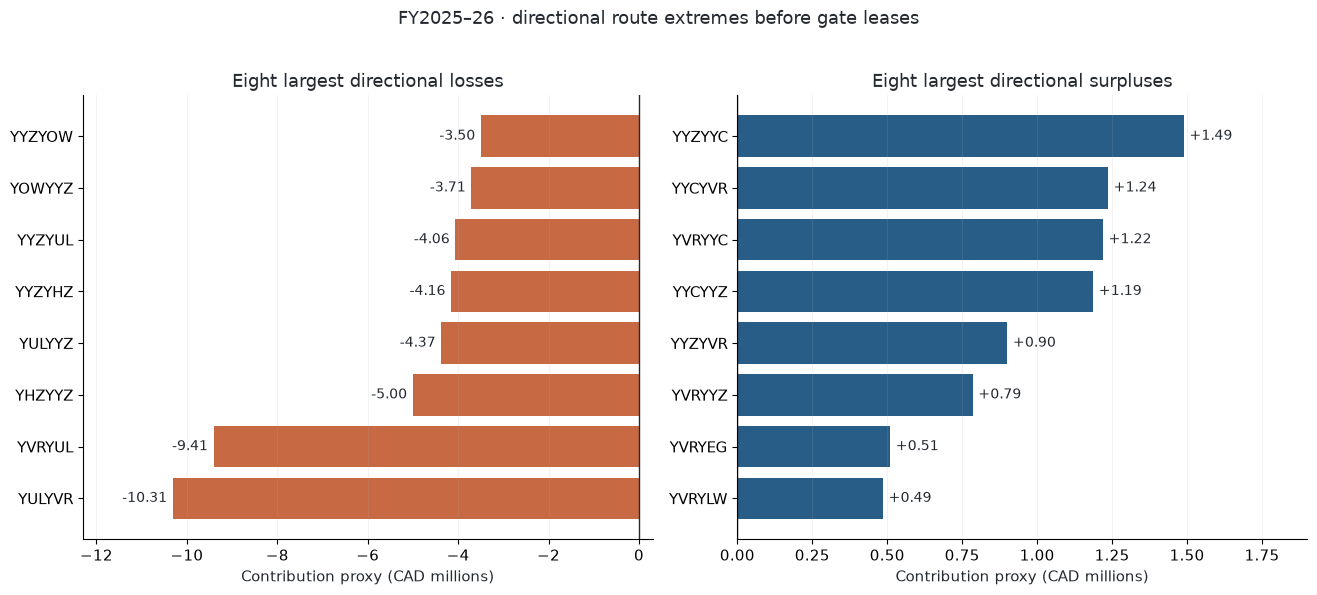

Direction,Revenue (CAD),Flight costs (CAD),Contribution (CAD),Margin (%),Flights,Contribution / flight (CAD)
YULYVR,"9,316,132.63","19,629,342.96","-10,313,210.33",-110.70,306,"-33,703.30"
YVRYUL,"8,479,397.06","17,889,173.63","-9,409,776.57",-110.97,314,"-29,967.44"
YHZYYZ,"4,759,969.81","9,764,294.01","-5,004,324.20",-105.13,372,"-13,452.48"
YULYYZ,"4,419,157.32","8,791,986.88","-4,372,829.56",-98.95,628,"-6,963.10"
YYZYHZ,"3,973,639.15","8,129,783.93","-4,156,144.78",-104.59,344,"-12,081.82"
YYZYUL,"4,188,926.30","8,249,976.29","-4,061,049.99",-96.95,634,"-6,405.44"
YOWYYZ,"3,450,289.53","7,157,163.61","-3,706,874.08",-107.44,1038,"-3,571.17"
YYZYOW,"3,301,494.50","6,798,697.29","-3,497,202.79",-105.93,1062,"-3,293.03"
YHZYUL,"2,001,515.10","4,203,219.47","-2,201,704.37",-110.00,224,"-9,829.04"
YULYHZ,"1,852,262.05","3,886,459.48","-2,034,197.43",-109.82,228,"-8,921.92"


Montreal→Vancouver (CAD -10,313,210.33) and Vancouver→Montreal (CAD -9,409,776.57) are the largest directional losses. The eight losses shown total **CAD 44.52m**, or **72.9%** of the gross route loss pool. Toronto→Calgary is the largest surplus at CAD 1,489,304.01. This concentration argues for scrutinizing these corridors before assuming small communities explain the airline-wide problem.

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13.3, 5.8))
for ax, data, title, color in [
    (
        axes[0],
        negative_latest.head(8).sort_values("contribution_cad"),
        "Eight largest directional losses",
        COLORS["orange"],
    ),
    (
        axes[1],
        positive_latest.head(8).sort_values("contribution_cad"),
        "Eight largest directional surpluses",
        COLORS["blue"],
    ),
]:
    bars = ax.barh(data.route_id, data.contribution_cad / 1e6, color=color)
    labels = [f"{v/1e6:+.2f}" for v in data.contribution_cad]
    ax.bar_label(bars, labels=labels, padding=4, fontsize=10)
    ax.axvline(0, color="#252A30", linewidth=1)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("Contribution proxy (CAD millions)")
    ax.grid(axis="x", alpha=0.16)
axes[0].set_xlim(-12.3, 0.3)
axes[1].set_xlim(0, 1.9)
fig.suptitle("FY2025–26 · directional route extremes before gate leases", y=1.02)
fig.tight_layout()
save_figure(fig, "02_route_extremes")
plt.show()
cols = [
    "route_id",
    "revenue_cad",
    "operating_cost_cad",
    "contribution_cad",
    "contribution_margin_pct",
    "flights",
    "contribution_per_flight_cad",
]
show_table(
    negative_latest.head(10)[cols],
    {c: "{:,.2f}" for c in cols if c not in ["route_id", "flights"]},
)
display(
    Markdown(
        f"Montreal→Vancouver ({money(negative_latest.iloc[0].contribution_cad)}) and Vancouver→Montreal ({money(negative_latest.iloc[1].contribution_cad)}) are the largest directional losses. The eight losses shown total **{million(-negative_latest.head(8).contribution_cad.sum())}**, or **{100*(-negative_latest.head(8).contribution_cad.sum())/pools.iloc[1].loss_pool_cad:.1f}%** of the gross route loss pool. Toronto→Calgary is the largest surplus at {money(positive_latest.iloc[0].contribution_cad)}. This concentration argues for scrutinizing these corridors before assuming small communities explain the airline-wide problem."
    )
)

The next chart asks a different question: **where did contribution worsen most?** It ranks the difference between the two annual route proxies. This avoids confusing the largest present loss with the largest cause of deterioration.

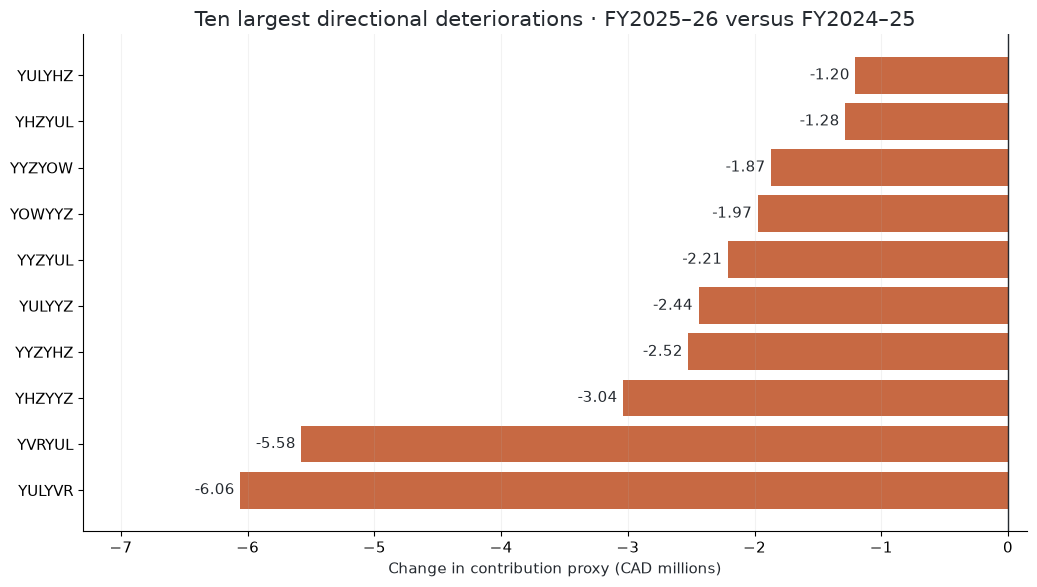

Direction,FY2024–25 (CAD),FY2025–26 (CAD),Change (CAD)
YYZYYT,"12,414.29","-155,396.62","-167,810.91"
YVRYXY,"92,533.92","-39,040.00","-131,573.92"
YXYYVR,"18,562.24","-97,122.42","-115,684.66"
YHZYYT,"20,929.51","-62,839.92","-83,769.43"


The eight largest deteriorations—both directions of Montreal↔Vancouver, Halifax↔Toronto, Montreal↔Toronto, and Ottawa↔Toronto—explain **CAD 25.69m (71.2%)** of the total decline. All eight were already negative in FY2024–25. Four directions newly turn negative: YYZYYT, YVRYXY, YXYYVR, YHZYYT. The new negative routes matter, but the larger issue is deepening losses on existing problem corridors.

In [6]:
worsening = route_change.head(10).sort_values("change_cad")
fig, ax = plt.subplots(figsize=(10.5, 6))
bars = ax.barh(worsening.route_id, worsening.change_cad / 1e6, color=COLORS["orange"])
ax.bar_label(bars, labels=[f"{v/1e6:+.2f}" for v in worsening.change_cad], padding=4)
ax.axvline(0, color="#252A30", linewidth=1)
ax.set_xlim(-7.3, 0.15)
ax.set_xlabel("Change in contribution proxy (CAD millions)")
ax.set_title("Ten largest directional deteriorations · FY2025–26 versus FY2024–25")
ax.grid(axis="x", alpha=0.16)
fig.tight_layout()
save_figure(fig, "02_route_deterioration")
plt.show()
switches = route_change.loc[
    route_change.fy2024_25_contribution_cad.gt(0)
    & route_change.fy2025_26_contribution_cad.lt(0)
]
show_table(
    switches[
        [
            "route_id",
            "fy2024_25_contribution_cad",
            "fy2025_26_contribution_cad",
            "change_cad",
        ]
    ],
    {
        c: "{:,.2f}"
        for c in [
            "fy2024_25_contribution_cad",
            "fy2025_26_contribution_cad",
            "change_cad",
        ]
    },
)
display(
    Markdown(
        f"The eight largest deteriorations—both directions of Montreal↔Vancouver, Halifax↔Toronto, Montreal↔Toronto, and Ottawa↔Toronto—explain **{million(top8_decline)} ({100*top8_decline/(-change_total):.1f}%)** of the total decline. All eight were already negative in FY2024–25. Four directions newly turn negative: {', '.join(switches.route_id)}. The new negative routes matter, but the larger issue is deepening losses on existing problem corridors."
    )
)

### 3. Departure airports: additive accountability, not complete airport economics

An airport's result is the sum of all routes **departing** there. It excludes inbound flights and local gate leases, and does not value connectivity. Grouping by airport helps locate where the current route mix is positive or negative without duplicating network totals.

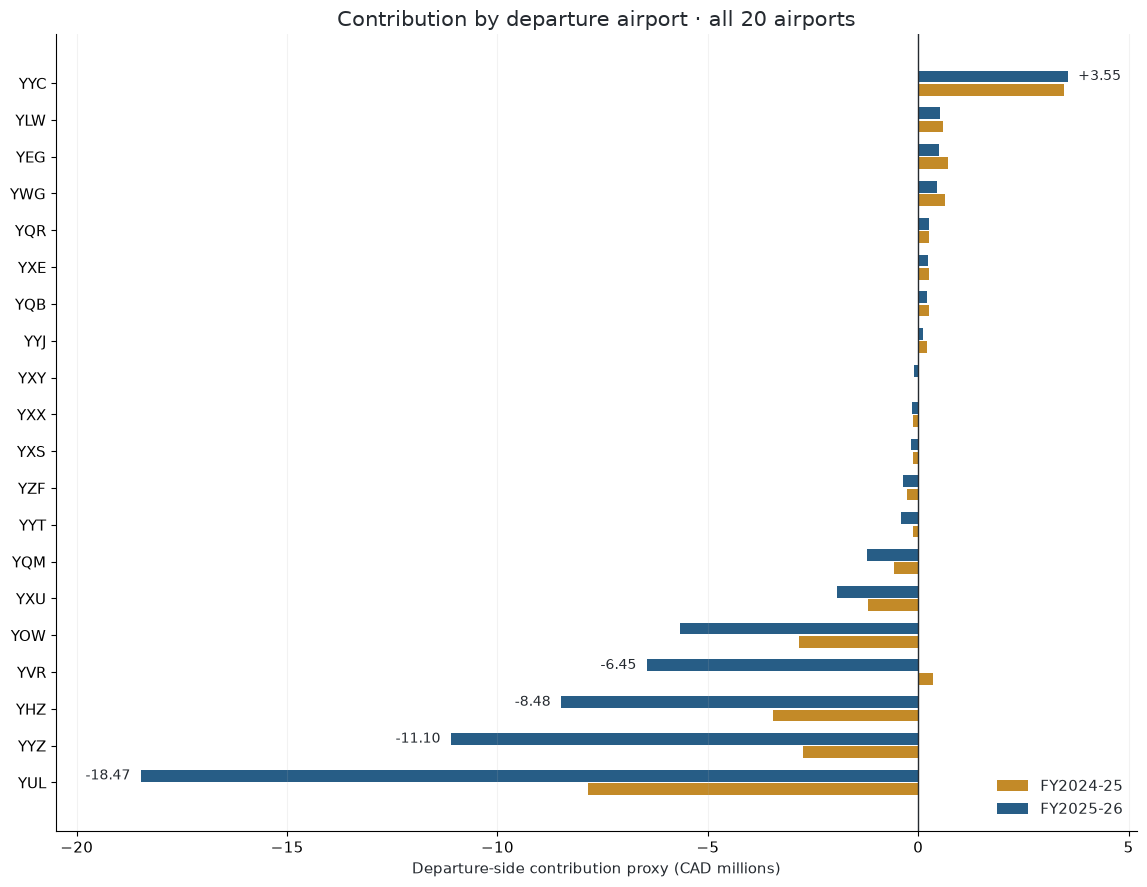

Departure,Directions,Positive routes,Contribution (CAD),Margin (%),Flights
YUL,5,1,"-18,473,719.22",-101.9,1941
YYZ,8,3,"-11,103,172.56",-23.3,3259
YHZ,4,0,"-8,484,239.05",-98.7,1000
YVR,8,5,"-6,446,912.20",-14.5,2289
YOW,2,0,"-5,661,405.81",-128.5,1582
YXU,1,0,"-1,921,450.47",-206.7,530
YQM,1,0,"-1,223,358.79",-210.5,336
YYT,2,0,"-416,599.78",-9.0,168
YZF,1,0,"-355,250.87",-24.3,86
YXS,1,0,"-175,809.26",-14.8,159


**8 of 20 departure airports are positive** in FY2025–26, compared with 10 previously. Calgary remains the largest positive departure portfolio at **CAD 3,550,134.34**. Montreal, Toronto, Halifax, and Vancouver have the largest negative totals. Vancouver's CAD -6.45m total includes the CAD -9.41m Montreal direction: excluding that single direction leaves **CAD 2.96m** across its other departures. This is a concentration diagnostic, not a closure-savings estimate.

In [7]:
airport_order = (
    airport.loc[airport.fiscal_year.eq(FY_ORDER[1])]
    .sort_values("contribution_cad")
    .departure_airport.tolist()
)
airport_pivot = airport.pivot(
    index="departure_airport", columns="fiscal_year", values="contribution_cad"
).reindex(airport_order)
fig, ax = plt.subplots(figsize=(11.6, 9))
y = np.arange(len(airport_order))
for offset, fy, color in [
    (-0.18, FY_ORDER[0], COLORS["gold"]),
    (0.18, FY_ORDER[1], COLORS["blue"]),
]:
    ax.barh(y + offset, airport_pivot[fy] / 1e6, height=0.32, label=fy, color=color)
ax.set_yticks(y, airport_order)
ax.axvline(0, color="#252A30", linewidth=1)
ax.set_xlim(-20.5, 5.2)
ax.set_xlabel("Departure-side contribution proxy (CAD millions)")
ax.set_title("Contribution by departure airport · all 20 airports")
ax.grid(axis="x", alpha=0.16)
ax.legend(loc="lower right", frameon=False)
for code in ["YUL", "YYZ", "YHZ", "YVR", "YYC"]:
    i = airport_order.index(code)
    val = airport_pivot.loc[code, FY_ORDER[1]] / 1e6
    ax.text(
        val + (-0.25 if val < 0 else 0.25),
        i + 0.18,
        f"{val:+.2f}",
        va="center",
        ha="right" if val < 0 else "left",
        fontsize=10,
    )
fig.tight_layout()
save_figure(fig, "02_departure_airports")
plt.show()
latest_airport = airport.loc[airport.fiscal_year.eq(FY_ORDER[1])].sort_values(
    "contribution_cad"
)
show_table(
    latest_airport[
        [
            "departure_airport",
            "directional_routes",
            "profitable_routes",
            "contribution_cad",
            "contribution_margin_pct",
            "flights",
        ]
    ],
    {"contribution_cad": "{:,.2f}", "contribution_margin_pct": "{:,.1f}"},
)
vancouver_current = latest_airport.loc[
    latest_airport.departure_airport.eq("YVR"), "contribution_cad"
].iloc[0]
vancouver_without_montreal = (
    vancouver_current
    - latest.loc[latest.route_id.eq("YVRYUL"), "contribution_cad"].iloc[0]
)
display(
    Markdown(
        f"**{int(latest_airport.contribution_cad.gt(0).sum())} of 20 departure airports are positive** in FY2025–26, compared with {int(airport.loc[airport.fiscal_year.eq(FY_ORDER[0]),'contribution_cad'].gt(0).sum())} previously. Calgary remains the largest positive departure portfolio at **{money(latest_airport.loc[latest_airport.departure_airport.eq('YYC'),'contribution_cad'].iloc[0])}**. Montreal, Toronto, Halifax, and Vancouver have the largest negative totals. Vancouver's {million(vancouver_current)} total includes the {million(latest.loc[latest.route_id.eq('YVRYUL'),'contribution_cad'].iloc[0])} Montreal direction: excluding that single direction leaves **{million(vancouver_without_montreal)}** across its other departures. This is a concentration diagnostic, not a closure-savings estimate."
    )
)

### 4. Network segments: broad weakness masks profitable routes within groups

The four groups are mutually exclusive and exhaustive. “Non-hub” includes diverse airports, including Edmonton and Halifax; it is **not** a synonym for a remote community. Do not infer a north-versus-south or urban-versus-rural result from this classification.

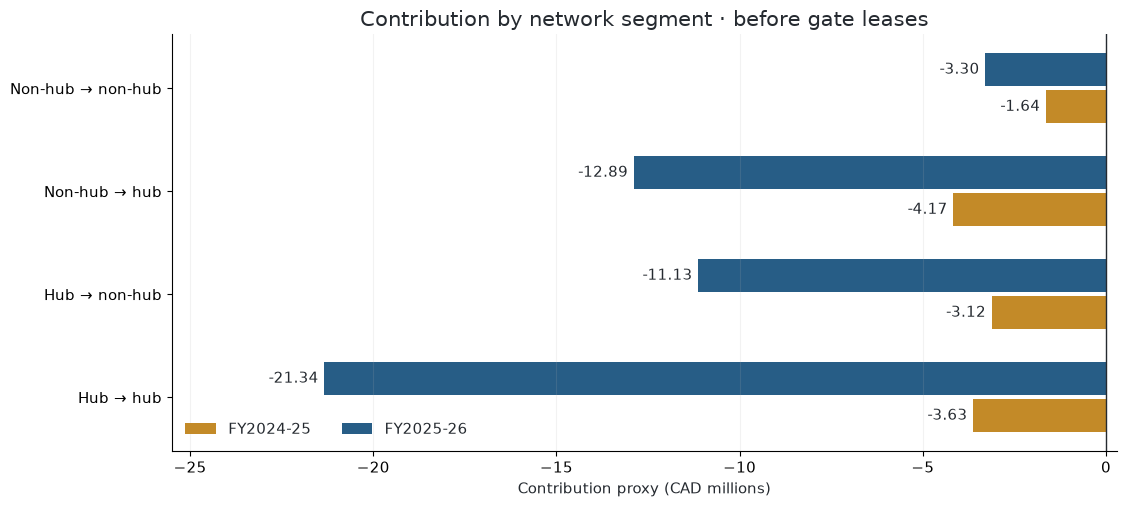

Segment,Directions,Positive routes,Revenue (CAD),Contribution (CAD),Margin (%),Flights,Contribution / flight (CAD)
Hub → hub,10,6,"93,795,702.33","-21,338,816.16",-22.8,3518,"-6,065.61"
Hub → non-hub,19,10,"43,882,831.27","-11,134,853.48",-25.4,5628,"-1,978.47"
Non-hub → hub,19,10,"45,052,683.77","-12,891,914.06",-28.6,5585,"-2,308.31"
Non-hub → non-hub,6,0,"6,979,154.43","-3,300,520.75",-47.3,998,"-3,307.14"


Corridor,Contribution (CAD),Flights
YUL ↔ YVR,"-19,722,986.90",620
YHZ ↔ YYZ,"-9,160,468.98",716
YUL ↔ YYZ,"-8,433,879.55",1262
YOW ↔ YYZ,"-7,204,076.87",2100
YHZ ↔ YUL,"-4,235,901.80",452
YOW ↔ YUL,"-3,951,146.72",1090
YXU ↔ YYZ,"-3,878,819.74",1064
YHZ ↔ YQM,"-2,438,729.35",668


Every segment is net negative. **Hub→hub accounts for CAD 21.34m, or 43.8% of the airline's net contribution deficit**; this denominator is net airline loss, unlike the gross route loss pool used above. Yet 6 of its ten directions are positive. Non-hub→non-hub is the only group with no positive routes. These results support route-specific redesign rather than a blanket rule to cut all hub services or all regional services. The two-way corridor table confirms that the largest directional losses remain losses after combining their return legs; 27 corridors each contain exactly two directions.

In [8]:
segment_pivot = segment.pivot(
    index="segment", columns="fiscal_year", values="contribution_cad"
).reindex(SEGMENTS)
fig, ax = plt.subplots(figsize=(11.4, 5.2))
y = np.arange(4)
for offset, fy, color in [
    (-0.18, FY_ORDER[0], COLORS["gold"]),
    (0.18, FY_ORDER[1], COLORS["blue"]),
]:
    bars = ax.barh(
        y + offset, segment_pivot[fy] / 1e6, height=0.32, label=fy, color=color
    )
    ax.bar_label(bars, labels=[f"{v/1e6:+.2f}" for v in segment_pivot[fy]], padding=4)
ax.set_yticks(y, SEGMENTS)
ax.axvline(0, color="#252A30", linewidth=1)
ax.set_xlim(-25.5, 0.3)
ax.set_xlabel("Contribution proxy (CAD millions)")
ax.set_title("Contribution by network segment · before gate leases")
ax.legend(loc="lower left", frameon=False, ncol=2)
ax.grid(axis="x", alpha=0.16)
fig.tight_layout()
save_figure(fig, "02_network_segments")
plt.show()
show_table(
    segment.loc[segment.fiscal_year.eq(FY_ORDER[1])]
    .set_index("segment")
    .reindex(SEGMENTS)
    .reset_index()[
        [
            "segment",
            "directional_routes",
            "profitable_routes",
            "revenue_cad",
            "contribution_cad",
            "contribution_margin_pct",
            "flights",
            "contribution_per_flight_cad",
        ]
    ],
    {
        "revenue_cad": "{:,.2f}",
        "contribution_cad": "{:,.2f}",
        "contribution_margin_pct": "{:,.1f}",
        "contribution_per_flight_cad": "{:,.2f}",
    },
)
hub_loss = -segment_pivot.loc["Hub → hub", FY_ORDER[1]]
latest_corridor = corridor.loc[corridor.fiscal_year.eq(FY_ORDER[1])].sort_values(
    "contribution_cad"
)
show_table(
    latest_corridor.head(8)[["corridor", "contribution_cad", "flights"]],
    {"contribution_cad": "{:,.2f}"},
)
display(
    Markdown(
        f"Every segment is net negative. **Hub→hub accounts for {million(hub_loss)}, or {100*hub_loss/(-annual.iloc[1].contribution_cad):.1f}% of the airline's net contribution deficit**; this denominator is net airline loss, unlike the gross route loss pool used above. Yet {int(segment.loc[segment.fiscal_year.eq(FY_ORDER[1]) & segment.segment.eq('Hub → hub'),'profitable_routes'].iloc[0])} of its ten directions are positive. Non-hub→non-hub is the only group with no positive routes. These results support route-specific redesign rather than a blanket rule to cut all hub services or all regional services. The two-way corridor table confirms that the largest directional losses remain losses after combining their return legs; 27 corridors each contain exactly two directions."
    )
)

## Takeaways

1. **There is a cross-subsidy burden in the accounting-proxy sense.** Positive route contributions offset negative ones, but their coverage has collapsed. The profitable pool cannot support the current loss pool or the additional gate overhead.
2. **Prioritize the large problem corridors.** Montreal↔Vancouver and the Toronto links to Halifax, Montreal, and Ottawa explain most of the deterioration. Review frequency, schedule, fleet fit, pricing, and purchase-to-flight timing at route and season level before deciding what capacity to change.
3. **Protect the useful distinctions.** Calgary departures are positive, multiple hub directions are positive, and several smaller-airport departures are positive. Broad labels conceal this variation. Directional and return-leg totals should both inform network decisions.
4. **Require incremental economics before a cut.** Supplied flight costs are recorded costs, not proven cash-avoidable costs. Crew, aircraft and overhead may persist after a cut; connecting passengers may generate contribution elsewhere. Booking IDs identify multi-leg tickets but do not supply a reliable departure itinerary or causal recapture estimate. Network spillovers and community consequences require additional evidence.

### Limits and next evidence

This is not accrual profit or true flight-level margin: revenue has purchase dates and flights have operating dates. No seats, aircraft, load factor, flight identifier, fuel volume, stage distance, inventory constraints, customer alternatives, or controllable/fixed cost split are supplied. Four rows per route/timestamp validate the available flight proxy, but simultaneous same-route flights would still be indistinguishable. Full profitability also requires gate leases and other omitted expenses. Gate costs should be assessed separately with their calendar lease periods and missing 2026–27 data. The day-first assumption changes the transaction population; the exported audit makes its exclusions explicit.

### Reproducibility and artifacts

Run this notebook from the project root with `.venv/bin/python` and the `firstbyte` Jupyter kernel. The shared loader in `src/analysis_common.py` applies scope and integer-cent conversion. Every aggregation reconciles independently to the source totals; airport, segment and corridor totals match the route view. Execution saves five figures in PNG and SVG, complete CSV evidence tables prefixed `02_`, and the plain-text handoff report below.

## Answer to Question 2

**How does financial performance differ across the network, and are some operations carrying others?** Performance differs sharply by direction and airport, and profitable routes offset only a small part of the losses elsewhere. These are **pre-gate contribution proxies**, using net purchase-date revenue less flight-date fuel, crew, maintenance and food costs.

- **Directional routes:** 26 of 54 directions were positive in FY2025–26, down from 30. Toronto→Calgary led at **CAD 1,489,304.01**, followed by Calgary→Vancouver (CAD 1,236,277.53), Vancouver→Calgary (CAD 1,219,640.04), and Calgary→Toronto (CAD 1,187,012.01). The largest losses were Montreal→Vancouver (**CAD −10,313,210.33**) and Vancouver→Montreal (**CAD −9,409,776.57**). Together they consumed **CAD 19,722,986.90**, **32.3% of the gross loss pool**. Both directions of Montreal↔Vancouver, Halifax↔Toronto, Montreal↔Toronto and Ottawa↔Toronto explain **CAD 25,687,713.86, or 71.2%**, of the CAD 36,099,983.54 deterioration. These eight directions were already negative in the first year: deepening established losses are the main review priority.
- **Airports:** 8 of 20 departure portfolios were positive, versus 10 previously: **Calgary, Kelowna, Edmonton, Winnipeg, Regina, Saskatoon, Quebec City and Victoria**. Calgary led at **CAD +3,550,134.34**. Montreal (**CAD −18,473,719.22**), Toronto (CAD −11,103,172.56), Halifax (CAD −8,484,239.05), Vancouver (CAD −6,446,912.20) and Ottawa (CAD −5,661,405.81) were the largest negatives. These totals assign each direction only to its departure airport. Vancouver's other departures, excluding Montreal, contributed **CAD +2,962,864.37**; a negative airport total can conceal useful routes.
- **Network segments:** all four defined groups were negative in FY2025–26: hub→hub **CAD −21,338,816.16**, hub→non-hub **CAD −11,134,853.48**, non-hub→hub **CAD −12,891,914.06**, and non-hub→non-hub **CAD −3,300,520.75**. Hub→hub represents **43.8% of the net airline contribution deficit**, but 6 of its 10 directions are positive. Each hub-related group contains positive routes; the six non-hub→non-hub directions are all negative. Broad labels therefore do not justify a blanket regional-service or hub-service cut.
- **Cross-subsidy:** the 26 positive directions earned **CAD 12,369,894.81**, offsetting **20.3%** of the **CAD 61,035,999.26** consumed by the 28 negative directions. The earlier year's surplus was **CAD 14,872,348.92**, covering **54.2%** of CAD 27,438,469.83 of losses. The positive cushion shrank by CAD 2,502,454.11 while the gross loss pool grew by CAD 33,597,529.43. Thus profitable operations are carrying part of the burden, but leave **CAD 48,666,104.45** uncovered before gate leases.

**Business meaning:** prioritize the largest deteriorating corridors for schedule, fleet, pricing and frequency review while preserving distinctions between profitable and weak directions. The data confirm financial concentration and the shrinking offset from positive routes; they do **not** establish that removing a negative route would save its entire recorded cost or improve network profit. Some costs persist, and connecting demand can support another route.

**What remains assumed or unconfirmed:** revenue and costs use different timing bases, so matched-flight/accrual profitability is unconfirmed. Gate leases and other omitted overhead would change fully loaded results. The user-directed day-first assumption excludes **759 transactions / CAD 499,209.97** outside the stated horizon; parsed and duplicate-resolved timestamps remain unchanged. Four-category flight grain, full directional-route coverage, and source-to-route-to-airport/segment reconciliations are confirmed. Flight occupancy, avoidable costs and connection spillovers require further data before capacity or closure decisions.
